<a href="https://colab.research.google.com/github/Rageel-28/PCVK_Ganjil_2026/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 7 – Segmentasi Citra dengan Thresholding
**Mata kuliah:** Pengolahan Citra dan Visi Komputer – Jurusan Teknologi Informasi



## Persiapan (Tugas 1 dan 2)
Tugas 1

In [1]:
#Library yang digunakan
import re
import difflib
import cv2 as cv
from google.colab import files
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood
from sklearn.cluster import KMeans

In [2]:
# Fungsi bantu: upload gambar tanpa Google Drive
def upload_gambar(petunjuk, mode=cv.IMREAD_COLOR):
    """Menampilkan tombol upload, lalu mengembalikan (gambar, nama_file).
    mode: cv.IMREAD_COLOR (BGR) atau cv.IMREAD_GRAYSCALE."""
    print(petunjuk)
    hasil = files.upload()
    if not hasil:
        raise ValueError('Tidak ada file yang diupload. Jalankan ulang sel ini.')
    nama = list(hasil.keys())[-1]
    arr = np.frombuffer(hasil[nama], np.uint8)
    img = cv.imdecode(arr, mode)
    if img is None:
        raise ValueError(f'File {nama} bukan gambar yang valid.')
    print(f'Berhasil: {nama} | ukuran {img.shape}')
    return img, nama

---
# D1. TUGAS INDIVIDU

## Tugas 3 – Global Threshold Manual (T = 200)
Lima jenis global threshold dibuat **manual dengan NumPy** (tanpa `cv.threshold`). `cv.threshold` hanya dipakai di akhir untuk memeriksa kebenaran.

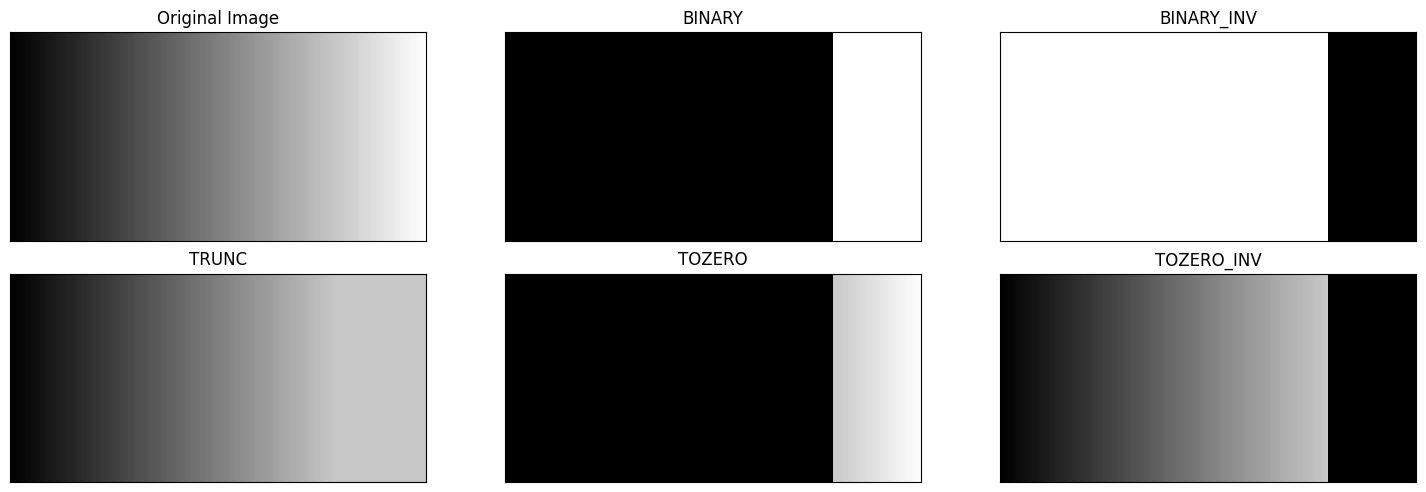

In [3]:
# Citra gradien hitam -> putih (setara gradient.jpg pada modul).
# Ubah ke True jika ingin upload gradient.jpg sendiri.
UPLOAD_GRADIEN = False

if UPLOAD_GRADIEN:
    img_grad, _ = upload_gambar('Upload gradient.jpg', cv.IMREAD_GRAYSCALE)
else:
    img_grad = np.tile(np.linspace(0, 255, 400).astype(np.uint8), (200, 1))

THRESH = 200
MAXVAL = 255

def global_threshold_manual(img, thresh, maxval, jenis):
    src = img.astype(np.int32)
    lebih = src > thresh                      # True jika nilai piksel > thresh
    if jenis == 'BINARY':
        dst = np.where(lebih, maxval, 0)      # > thresh -> maxval, selain itu 0
    elif jenis == 'BINARY_INV':
        dst = np.where(lebih, 0, maxval)      # > thresh -> 0, selain itu maxval
    elif jenis == 'TRUNC':
        dst = np.where(lebih, thresh, src)    # > thresh -> thresh, selain itu tetap
    elif jenis == 'TOZERO':
        dst = np.where(lebih, src, 0)         # > thresh -> tetap, selain itu 0
    elif jenis == 'TOZERO_INV':
        dst = np.where(lebih, 0, src)         # > thresh -> 0, selain itu tetap
    else:
        raise ValueError('Jenis threshold tidak dikenal')
    return dst.astype(np.uint8)

jenis_list = ['BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
hasil_global = {j: global_threshold_manual(img_grad, THRESH, MAXVAL, j) for j in jenis_list}

titles = ['Original Image'] + jenis_list
images = [img_grad] + [hasil_global[j] for j in jenis_list]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

In [4]:
# Verifikasi: bandingkan hasil manual dengan cv.threshold (hanya untuk pengecekan)
kode_cv = {'BINARY': cv.THRESH_BINARY, 'BINARY_INV': cv.THRESH_BINARY_INV,
           'TRUNC': cv.THRESH_TRUNC, 'TOZERO': cv.THRESH_TOZERO,
           'TOZERO_INV': cv.THRESH_TOZERO_INV}
for nama, kode in kode_cv.items():
    _, ref = cv.threshold(img_grad, THRESH, MAXVAL, kode)
    print(f'{nama:11s} sama dengan OpenCV:', np.array_equal(ref, hasil_global[nama]))

BINARY      sama dengan OpenCV: True
BINARY_INV  sama dengan OpenCV: True
TRUNC       sama dengan OpenCV: True
TOZERO      sama dengan OpenCV: True
TOZERO_INV  sama dengan OpenCV: True


## Tugas 4 – Adaptive Threshold Manual (Mean dan Gaussian)
Ketentuan: **tanpa** `cv.threshold()`, `cv.adaptiveThreshold()`, maupun fungsi filter siap pakai. Global threshold manual T = 127, jendela 11 × 11, C = 2, sigma = 2 untuk Gaussian.

Langkah: rata-rata lokal (atau Gaussian lokal) dihitung dengan menjumlahkan citra yang digeser (window b × b), lalu `T(x,y) = rata-rata − C`, dan piksel putih jika `I(x,y) > T(x,y)`.

In [5]:
img_sudoku, nama_sudoku = upload_gambar('Upload citra Sudoku (sudoku-original.jpg)', cv.IMREAD_GRAYSCALE)
gray_sudoku = img_sudoku

Upload citra Sudoku (sudoku-original.jpg)


Saving sudoku-original.jpg to sudoku-original.jpg
Berhasil: sudoku-original.jpg | ukuran (423, 419)


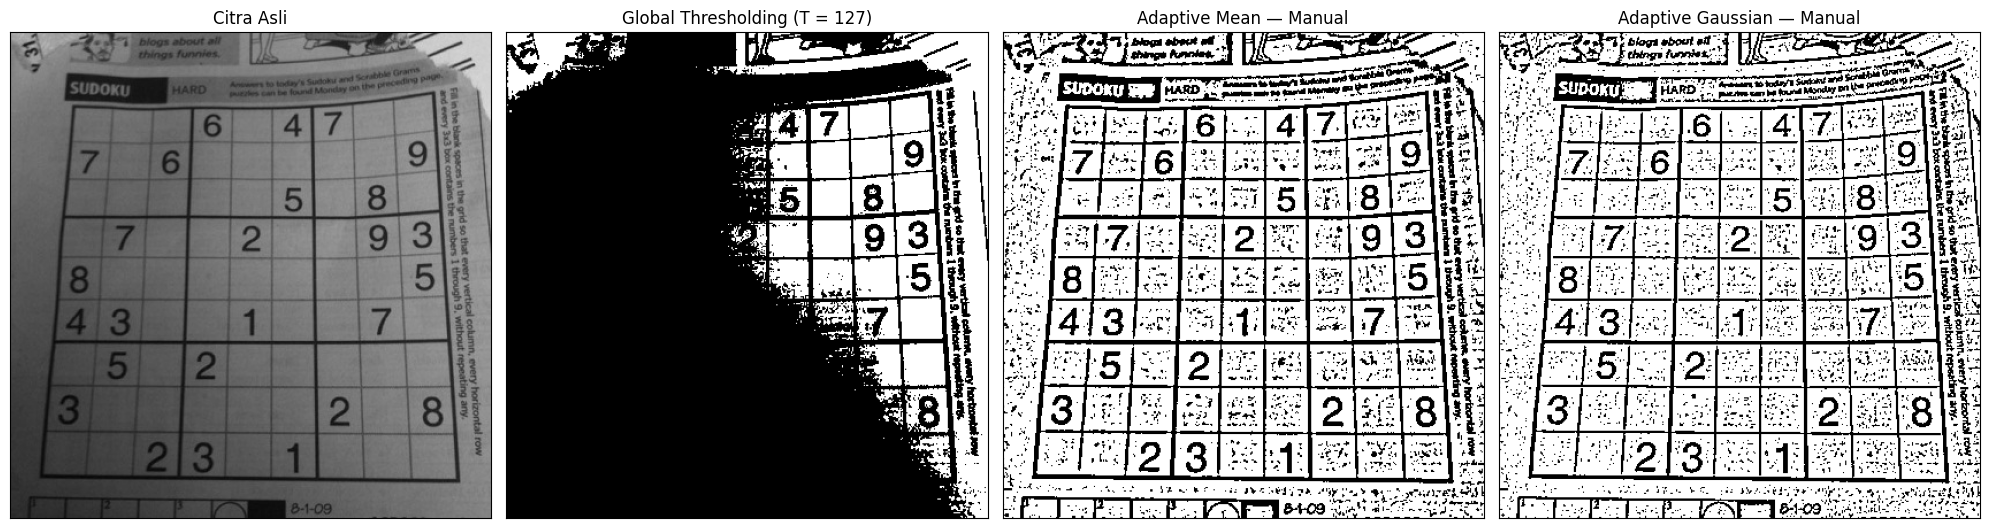

In [6]:
def pad_tepi(gray, b):
    r = b // 2
    return np.pad(gray.astype(np.float64), r, mode='edge')   # tepi diperluas (replicate)

def rata_rata_lokal(gray, b):
    H, W = gray.shape
    pad = pad_tepi(gray, b)
    total = np.zeros((H, W), dtype=np.float64)
    for dy in range(b):
        for dx in range(b):
            total += pad[dy:dy + H, dx:dx + W]
    return total / (b * b)

def kernel_gaussian(b, sigma):
    r = b // 2
    ax = np.arange(-r, r + 1)
    xx, yy = np.meshgrid(ax, ax)
    k = np.exp(-(xx ** 2 + yy ** 2) / (2.0 * sigma ** 2))
    return k / k.sum()                                        # dinormalisasi: jumlah bobot = 1

def gaussian_lokal(gray, b, sigma):
    H, W = gray.shape
    pad = pad_tepi(gray, b)
    k = kernel_gaussian(b, sigma)
    total = np.zeros((H, W), dtype=np.float64)
    for dy in range(b):
        for dx in range(b):
            total += k[dy, dx] * pad[dy:dy + H, dx:dx + W]
    return total

def adaptive_threshold_manual(gray, b, C, metode='mean', sigma=2):
    if b % 2 == 0:
        raise ValueError('Ukuran blok harus ganjil')
    mu = rata_rata_lokal(gray, b) if metode == 'mean' else gaussian_lokal(gray, b, sigma)
    T = mu - C                                  # ambang lokal T(x,y)
    return np.where(gray.astype(np.float64) > T, 255, 0).astype(np.uint8)

B, C, SIGMA, T_GLOBAL = 11, 2, 2, 127

th_global = global_threshold_manual(gray_sudoku, T_GLOBAL, 255, 'BINARY')
th_mean = adaptive_threshold_manual(gray_sudoku, B, C, 'mean')
th_gauss = adaptive_threshold_manual(gray_sudoku, B, C, 'gaussian', SIGMA)

titles = ['Citra Asli', f'Global Thresholding (T = {T_GLOBAL})',
          'Adaptive Mean — Manual', 'Adaptive Gaussian — Manual']
citra2 = [gray_sudoku, th_global, th_mean, th_gauss]

plt.figure(figsize=(20, 6))
for i in range(len(citra2)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(citra2[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

## Tugas 5A – Otsu Thresholding Manual (tanpa library)
Threshold dipilih dengan memaksimalkan *between-class variance* `σB² = Wb · Wf · (μb − μf)²`. Hasilnya dibandingkan dengan Otsu dari OpenCV (`cv.THRESH_OTSU`) dan global threshold T = 127.

In [7]:
img_lena, nama_lena = upload_gambar('Upload lena_gs_lc2.jpg', cv.IMREAD_GRAYSCALE)
blur = cv.GaussianBlur(img_lena, (5, 5), 0)
thresh = 127

Upload lena_gs_lc2.jpg


Saving lena_gs_lc2.png to lena_gs_lc2.png
Berhasil: lena_gs_lc2.png | ukuran (512, 512)


Threshold Otsu manual     : 93
Threshold Otsu OpenCV     : 92.0
Hasil biner sama persis?  : True


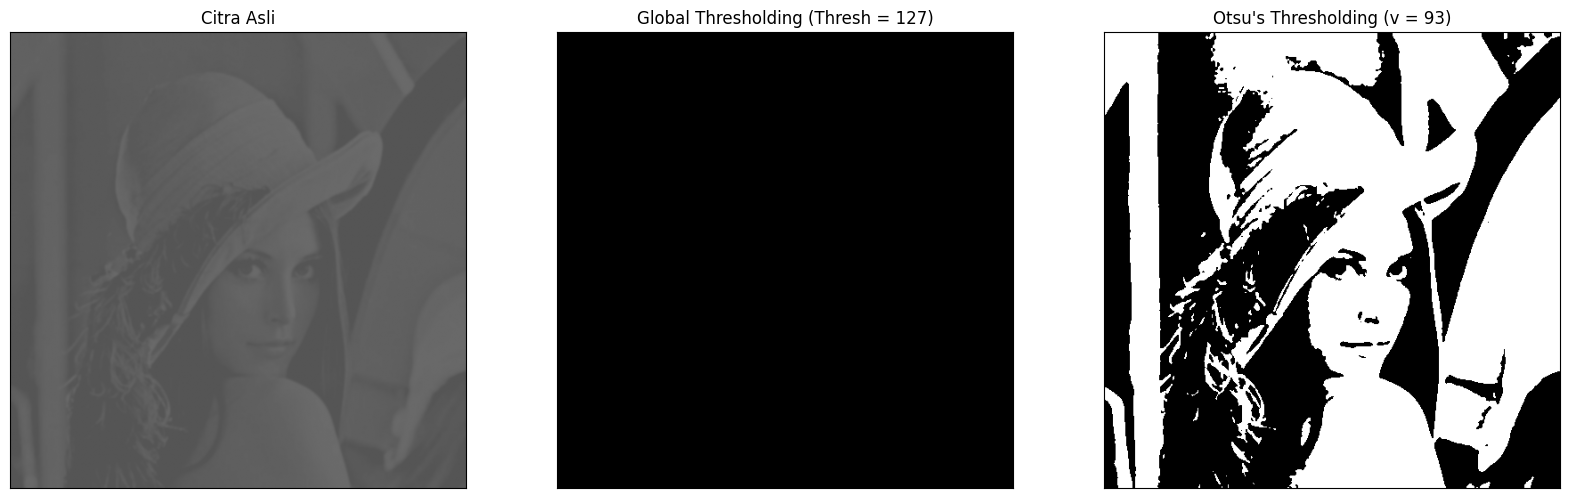

In [8]:
def otsu_manual(gray):
    total = gray.size
    his, _ = np.histogram(gray, bins=np.arange(0, 257))
    intensitas = np.arange(256)
    final_thresh, final_value = -1, -1.0
    for t in range(1, 256):                       # background: 0..t-1, foreground: t..255
        pcb, pcf = his[:t].sum(), his[t:].sum()
        if pcb == 0 or pcf == 0:                  # hindari pembagian dengan nol
            continue
        Wb, Wf = pcb / total, pcf / total
        mub = (intensitas[:t] * his[:t]).sum() / float(pcb)
        muf = (intensitas[t:] * his[t:]).sum() / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2        # between-class variance
        if value > final_value:
            final_thresh, final_value = t, value
    final_img = np.where(gray >= final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu_manual(blur)
print('Threshold Otsu manual     :', otsu_thresh)

# Pembanding: Otsu OpenCV (OpenCV melaporkan T sehingga piksel > T menjadi putih, jadi selisih 1)
ret_cv, otsu_cv = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Threshold Otsu OpenCV     :', ret_cv)
print('Hasil biner sama persis?  :', np.array_equal(otsu_biner, otsu_cv))

ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 7))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

### Pertanyaan: mengapa Binary Thresholding menghasilkan citra hitam semua? Berapa T supaya Lena masih terlihat?
Histogram berikut menunjukkan posisi T = 127 terhadap sebaran intensitas citra.

Rentang intensitas citra: 85 - 108
Jumlah piksel > 127     : 0 dari 262144


/tmp/ipykernel_1512/2158046567.py:7: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256], color='steelblue')


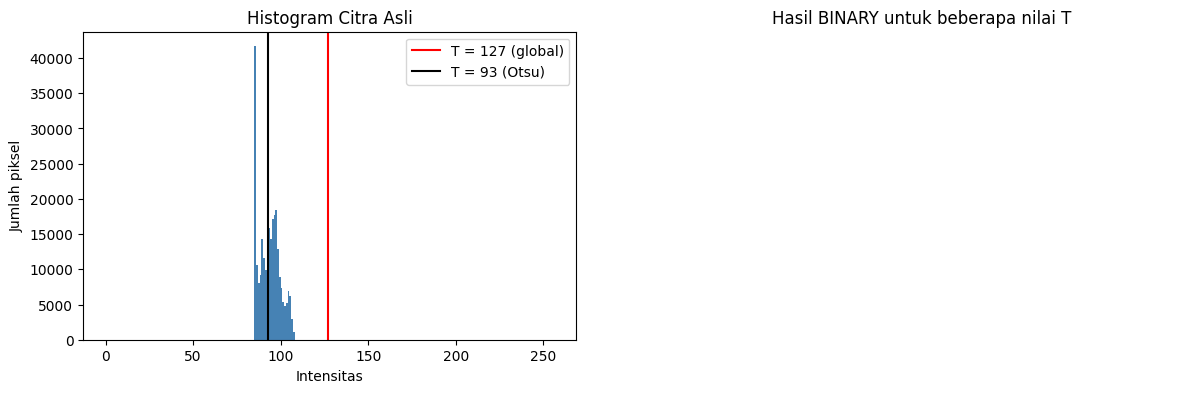

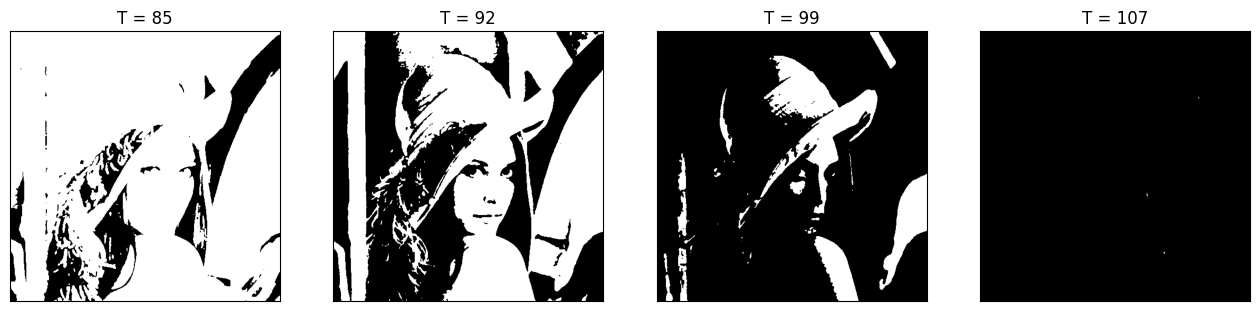

In [9]:
lo, hi = int(blur.min()), int(blur.max())
print(f'Rentang intensitas citra: {lo} - {hi}')
print(f'Jumlah piksel > 127     : {(blur > 127).sum()} dari {blur.size}')

plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
plt.hist(blur.ravel(), 256, [0, 256], color='steelblue')
plt.axvline(127, color='red', label='T = 127 (global)')
plt.axvline(otsu_thresh, color='black', label=f'T = {otsu_thresh} (Otsu)')
plt.title('Histogram Citra Asli')
plt.xlabel('Intensitas'), plt.ylabel('Jumlah piksel')
plt.legend()

# Uji beberapa nilai T di dalam rentang intensitas citra
T_uji = sorted(set(np.linspace(lo, hi - 1, 4).astype(int)))
plt.subplot(1, 2, 2)
plt.axis('off')
plt.title('Hasil BINARY untuk beberapa nilai T')
plt.show()

plt.figure(figsize=(16, 4))
for i, t in enumerate(T_uji):
    plt.subplot(1, len(T_uji), i + 1)
    plt.imshow(global_threshold_manual(blur, t, 255, 'BINARY'), 'gray', vmin=0, vmax=255)
    plt.title(f'T = {t}')
    plt.xticks([]), plt.yticks([])
plt.show()

**Jawaban (sesuaikan dengan angka dari output di atas):**
Citra Lena versi *low contrast* hanya memiliki intensitas sekitar 85–108, semuanya lebih kecil dari 127. Pada Binary Threshold, piksel dengan nilai ≤ T menjadi 0, jadi seluruh piksel berubah hitam. Pada histogram, garis merah T = 127 berada di kanan seluruh batang histogram, sehingga tidak ada piksel yang melewatinya.

Agar Lena masih terlihat, T harus berada di dalam rentang intensitas citra: **min ≤ T < max (kira-kira 85 ≤ T < 108)**. Nilai terbaik mendekati hasil Otsu, yaitu **sekitar 92–93**, karena titik itu memisahkan dua kelompok histogram.

## Tugas 5B – Otsu vs Global Threshold pada KTP sendiri
Upload gambar KTP (`ktp_fulan.jpg` atau KTP milik sendiri). Gambar ini juga dipakai kembali di Tugas 7 dan Tugas Kelompok.

Upload gambar KTP (ktp_fulan.jpg / KTP sendiri)


Saving ktp.jpg to ktp.jpg
Berhasil: ktp.jpg | ukuran (1008, 1600, 3)
Threshold Otsu pada KTP: 122


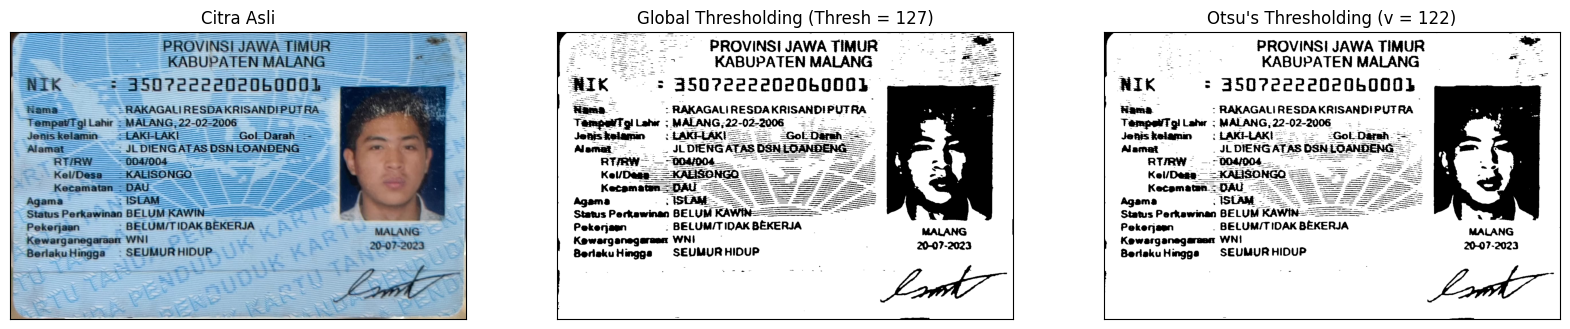

In [10]:
ktp_bgr, nama_ktp = upload_gambar('Upload gambar KTP (ktp_fulan.jpg / KTP sendiri)', cv.IMREAD_COLOR)
ktp_rgb = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)
ktp_blur = cv.GaussianBlur(ktp_gray, (5, 5), 0)

ktp_otsu, ktp_otsu_t = otsu_manual(ktp_blur)
ktp_global = global_threshold_manual(ktp_blur, 127, 255, 'BINARY')
print('Threshold Otsu pada KTP:', ktp_otsu_t)

plt.figure(figsize=(20, 5))
panel = [(ktp_rgb, 'Citra Asli'),
         (ktp_global, 'Global Thresholding (Thresh = 127)'),
         (ktp_otsu, f"Otsu's Thresholding (v = {ktp_otsu_t})")]
for i, (im, jd) in enumerate(panel):
    plt.subplot(1, 3, i + 1)
    if im.ndim == 2:
        plt.imshow(im, 'gray', vmin=0, vmax=255)
    else:
        plt.imshow(im)
    plt.title(jd)
    plt.xticks([]), plt.yticks([])
plt.show()

**Analisis singkat (isi sendiri berdasarkan hasil di atas):** bandingkan apakah teks KTP masih terbaca pada global threshold 127 dan pada Otsu, dan jelaskan alasannya dari sisi histogram (apakah latar KTP yang terang berada di atas atau di bawah 127).

## Tugas 6A – Region Growing Manual pada `data.coins()`
Ketentuan: 3 seed (di dalam koin, di latar, tepat di tepi koin), T = 5, 20, 60, hasil ditampilkan dalam grid 3 × 3 (seed × T).

Kriteria kesamaan: piksel tetangga (4 ketetanggaan) digabung jika `|I(q) − μ_region| < T`.

Ukuran citra: (303, 384)
Seed di dalam koin   (baris, kolom) = (36, 43) | intensitas = 159
Seed di latar        (baris, kolom) = (5, 5) | intensitas = 133
Seed di tepi koin    (baris, kolom) = (36, 52) | intensitas = 144


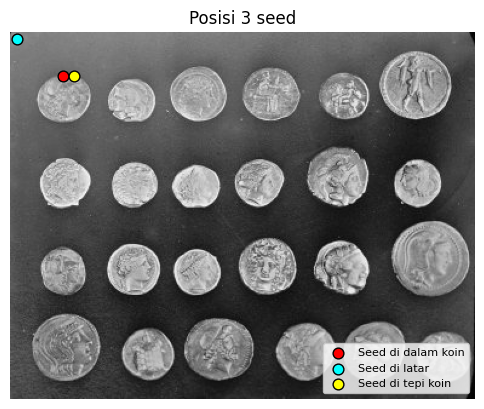

In [11]:
gray = data.coins()          # grayscale, 303 x 384
print('Ukuran citra:', gray.shape)

def region_growing(img, seed, T, conn=4):
    img = img.astype(np.float32)
    H, W = img.shape
    mask = np.zeros((H, W), dtype=bool)
    mask[seed] = True
    jumlah, jumlah_int = 1, float(img[seed])
    antrian = deque([seed])
    tetangga = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    if conn == 8:
        tetangga += [(-1, -1), (-1, 1), (1, -1), (1, 1)]
    while antrian:
        r, c = antrian.popleft()
        for dr, dc in tetangga:
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and not mask[rr, cc]:
                mu_region = jumlah_int / jumlah             # rata-rata region saat ini
                if abs(float(img[rr, cc]) - mu_region) < T:
                    mask[rr, cc] = True
                    antrian.append((rr, cc))
                    jumlah += 1
                    jumlah_int += float(img[rr, cc])
    return mask

# Seed 1: di dalam koin (koin pojok kiri atas), Seed 2: di latar
seed_koin = (36, 43)
seed_latar = (5, 5)

# Seed 3: tepat di tepi koin -> cari titik gradien terbesar pada baris yang sama, ke kanan dari pusat koin
profil = gray[seed_koin[0], seed_koin[1]: seed_koin[1] + 40].astype(float)
selisih = np.abs(np.diff(profil))
seed_tepi = (seed_koin[0], seed_koin[1] + int(np.argmax(selisih)))

seeds = {'Seed di dalam koin': seed_koin,
         'Seed di latar': seed_latar,
         'Seed di tepi koin': seed_tepi}
for nama, s in seeds.items():
    print(f'{nama:20s} (baris, kolom) = {s} | intensitas = {gray[s]}')

# Tampilkan posisi seed
plt.figure(figsize=(6, 5))
plt.imshow(gray, 'gray')
warna = ['red', 'cyan', 'yellow']
for (nama, s), w in zip(seeds.items(), warna):
    plt.scatter(s[1], s[0], c=w, s=60, edgecolors='black', label=nama)
plt.legend(loc='lower right', fontsize=8)
plt.title('Posisi 3 seed')
plt.axis('off')
plt.show()

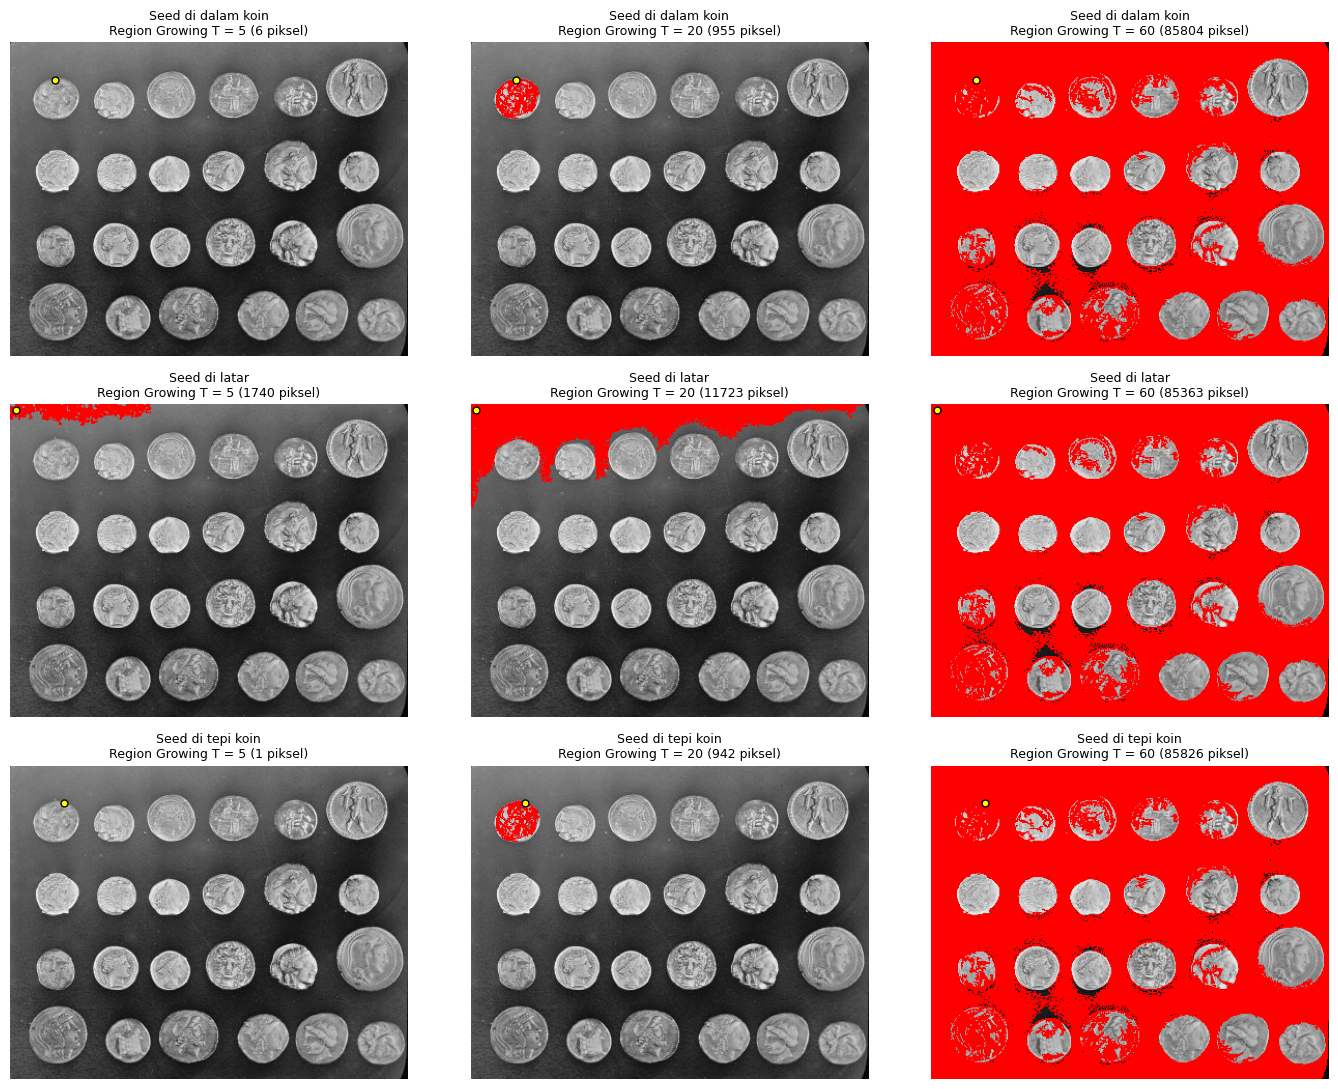

In [12]:
T_list = [5, 20, 60]

def overlay_merah(img, mask):
    rgb = np.dstack([img] * 3).copy()
    rgb[mask] = [255, 0, 0]
    return rgb

hasil_manual = {}
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for i, (nama, s) in enumerate(seeds.items()):
    for j, T in enumerate(T_list):
        m = region_growing(gray, s, T)
        hasil_manual[(nama, T)] = int(m.sum())
        axes[i, j].imshow(overlay_merah(gray, m))
        axes[i, j].scatter(s[1], s[0], c='yellow', s=25, edgecolors='black')
        axes[i, j].set_title(f'{nama}\nRegion Growing T = {T} ({int(m.sum())} piksel)', fontsize=9)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

## Tugas 6B – Region Growing dengan `skimage.segmentation.flood()`
`flood()` menerima piksel yang terhubung dan intensitasnya berada dalam **toleransi terhadap intensitas seed** (bukan terhadap rata-rata region seperti implementasi manual di atas), sehingga jumlah pikselnya bisa berbeda.

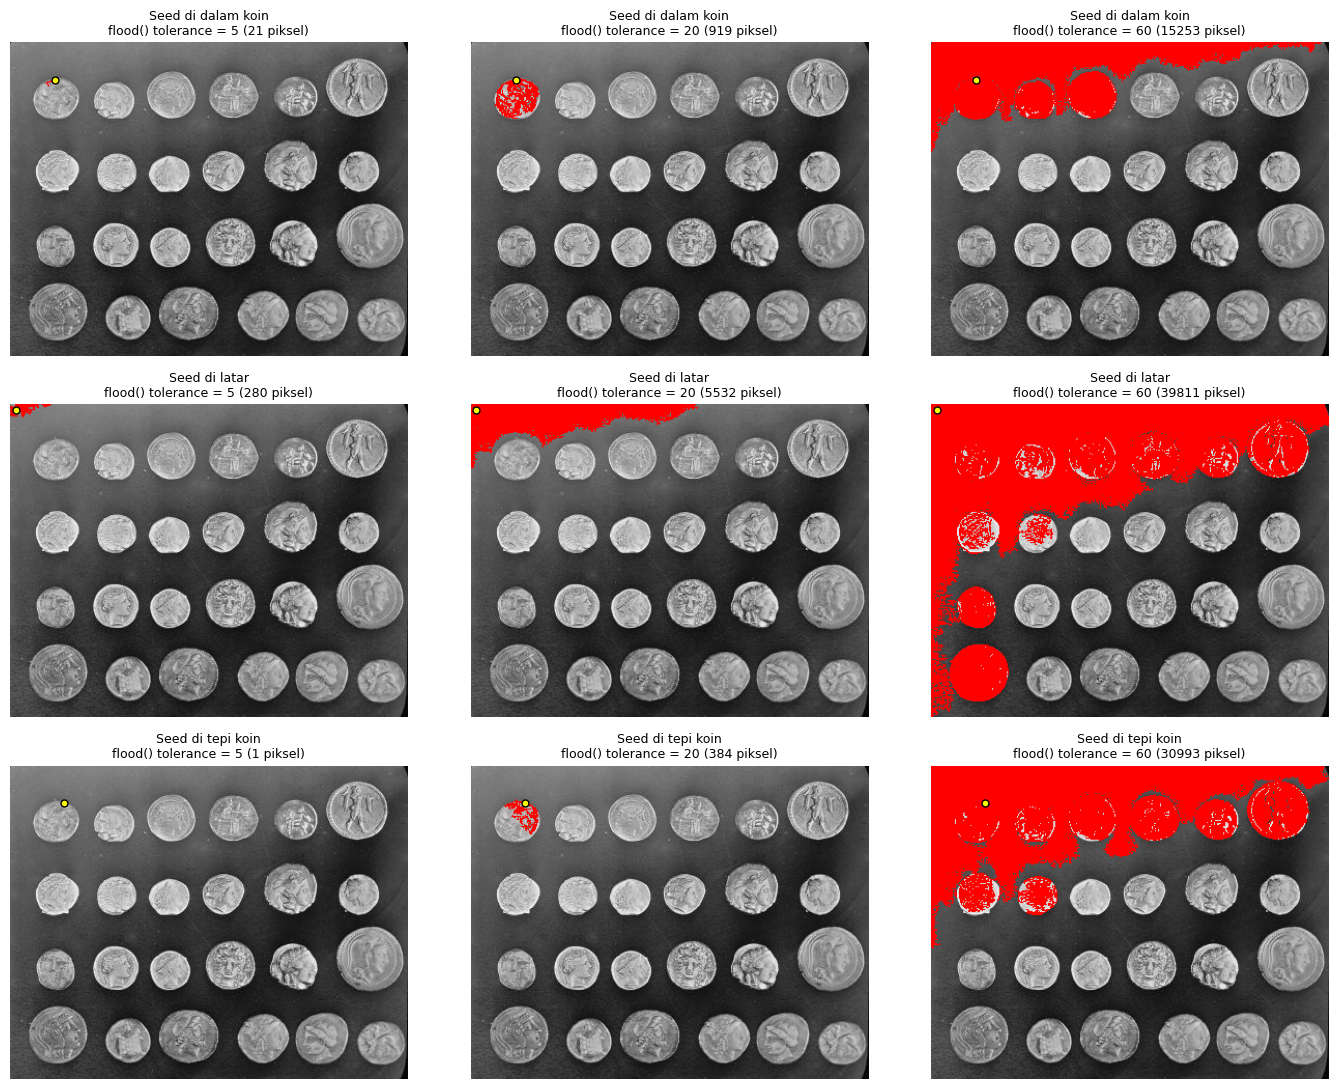

,Seed,T,Manual (piksel),flood() (piksel)
0,Seed di dalam koin,5,6,21
1,Seed di dalam koin,20,955,919
2,Seed di dalam koin,60,85804,15253
3,Seed di latar,5,1740,280
4,Seed di latar,20,11723,5532
5,Seed di latar,60,85363,39811
6,Seed di tepi koin,5,1,1
7,Seed di tepi koin,20,942,384
8,Seed di tepi koin,60,85826,30993


In [13]:
hasil_flood = {}
fig, axes = plt.subplots(3, 3, figsize=(14, 11))
for i, (nama, s) in enumerate(seeds.items()):
    for j, T in enumerate(T_list):
        region = flood(gray, seed_point=s, tolerance=T, connectivity=1)   # 4 tetangga untuk citra 2D
        hasil_flood[(nama, T)] = int(region.sum())
        axes[i, j].imshow(overlay_merah(gray, region))
        axes[i, j].scatter(s[1], s[0], c='yellow', s=25, edgecolors='black')
        axes[i, j].set_title(f'{nama}\nflood() tolerance = {T} ({int(region.sum())} piksel)', fontsize=9)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

# Perbandingan jumlah piksel manual vs flood()
baris = []
for nama in seeds:
    for T in T_list:
        baris.append({'Seed': nama, 'T': T,
                      'Manual (piksel)': hasil_manual[(nama, T)],
                      'flood() (piksel)': hasil_flood[(nama, T)]})
pd.DataFrame(baris)

**Analisis singkat (isi sendiri):** pengaruh T kecil (region hanya bercak), T sedang (satu koin terpisah), dan T besar (region "bocor" ke latar atau koin tetangga); serta perbedaan seed di dalam koin, di latar, dan di tepi koin.

## Tugas 7 – Segmentasi Warna: hanya warna biru pada KTP
Langkah: (1) K-Means (K = 8) pada warna RGB untuk menyederhanakan warna, (2) ubah hasilnya ke HSV, (3) pertahankan hanya piksel dengan `85 ≤ H ≤ 130`, `S ≥ 25`, `V ≥ 40` (skala H OpenCV 0–179); piksel lain dihitamkan.

Piksel biru: 1527068 dari 1612800 (94.7%)


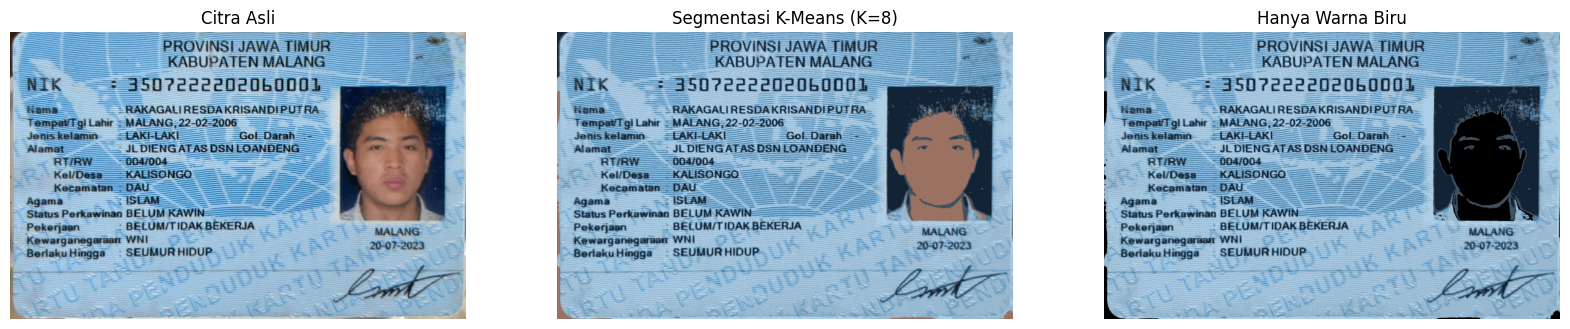

In [14]:
# memakai gambar KTP yang sudah diupload pada Tugas 5B
K = 8
Z = ktp_rgb.reshape((-1, 3)).astype(np.float32)

# K-Means dilatih pada sampel piksel agar cepat, lalu semua piksel diberi label
rng = np.random.default_rng(42)
idx = rng.choice(len(Z), size=min(30000, len(Z)), replace=False)
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10).fit(Z[idx])
labels = kmeans.predict(Z)
centers = np.uint8(kmeans.cluster_centers_)
segmented_img = centers[labels].reshape(ktp_rgb.shape)

# Ke HSV, lalu ambil hanya rentang biru
hsv = cv.cvtColor(segmented_img, cv.COLOR_RGB2HSV)
Hc, Sc, Vc = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
kelompok_biru = (Hc >= 85) & (Hc <= 130) & (Sc >= 25) & (Vc >= 40)

hanya_biru = np.zeros_like(segmented_img)
hanya_biru[kelompok_biru] = segmented_img[kelompok_biru]
print(f'Piksel biru: {kelompok_biru.sum()} dari {kelompok_biru.size} ({100 * kelompok_biru.mean():.1f}%)')

plt.figure(figsize=(20, 5))
for i, (im, jd) in enumerate([(ktp_rgb, 'Citra Asli'),
                              (segmented_img, f'Segmentasi K-Means (K={K})'),
                              (hanya_biru, 'Hanya Warna Biru')]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im)
    plt.title(jd)
    plt.axis('off')
plt.show()

---
# D2. TUGAS KELOMPOK – Perbandingan OCR pada KTP Berwarna, Otsu, dan Adaptive
Satu citra KTP **per anggota kelompok**. Jalankan notebook ini sekali untuk tiap anggota (ganti file KTP), lalu gabungkan tabel hasilnya di laporan.

**Nama anggota kelompok:** ............................

In [15]:
# Instal Tesseract OCR + model bahasa Indonesia, lalu pytesseract
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [16]:
import pytesseract
from pytesseract import Output

# Gunakan KTP yang sudah diupload sebelumnya. Ubah ke True untuk upload KTP lain (mis. KTP anggota berikutnya).
UPLOAD_ULANG_KTP = False
if UPLOAD_ULANG_KTP or 'ktp_bgr' not in globals():
    ktp_bgr, nama_ktp = upload_gambar('Upload KTP anggota kelompok', cv.IMREAD_COLOR)
print('KTP yang dipakai:', nama_ktp)

# Pengaturan OCR yang SAMA untuk ketiga citra
LANG = 'ind' if 'ind' in pytesseract.get_languages() else 'eng'
CONFIG = '--psm 6'
BATAS_CONF = 60
print('Bahasa OCR:', LANG, '| config:', CONFIG, '| batas confidence >', BATAS_CONF)

KTP yang dipakai: ktp.jpg
Bahasa OCR: ind | config: --psm 6 | batas confidence > 60


### Langkah 1 – Siapkan tiga citra (ukuran sama)

{'Berwarna': (630, 1000, 3), 'Otsu': (630, 1000), 'Adaptive': (630, 1000)}


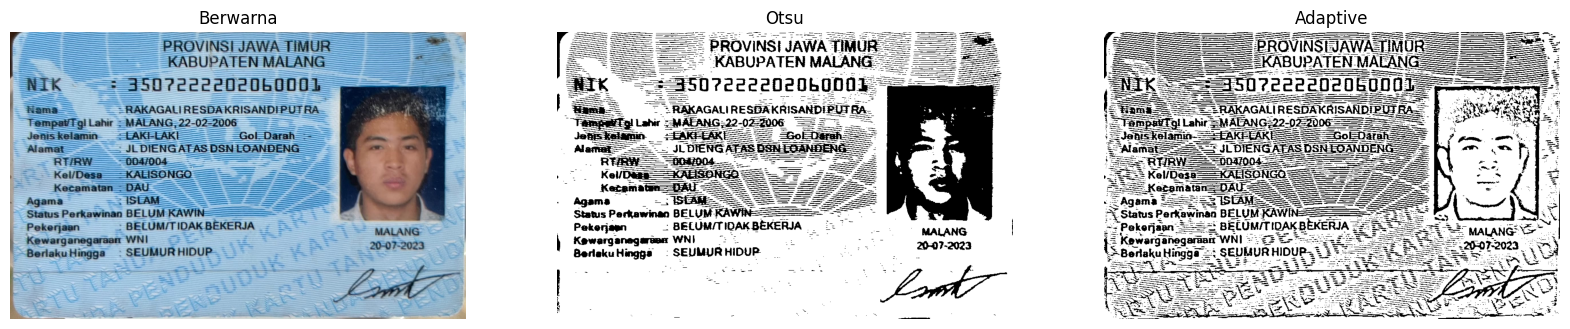

In [17]:
# Ukuran sama untuk ketiga citra
LEBAR = 1000
skala = LEBAR / ktp_bgr.shape[1]
ktp_resize = cv.resize(ktp_bgr, None, fx=skala, fy=skala, interpolation=cv.INTER_CUBIC)
gray_ocr = cv.cvtColor(ktp_resize, cv.COLOR_BGR2GRAY)          # grayscale untuk kedua metode threshold

# 1) Citra berwarna asli
img_warna = ktp_resize.copy()

# 2) Otsu Thresholding
_, img_otsu = cv.threshold(gray_ocr, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

# 3) Adaptive Thresholding (Gaussian). Boleh disetel: blockSize ganjil, C kecil-sedang
img_adaptive = cv.adaptiveThreshold(gray_ocr, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)

citra_ocr = {'Berwarna': img_warna, 'Otsu': img_otsu, 'Adaptive': img_adaptive}
print({k: v.shape for k, v in citra_ocr.items()})

plt.figure(figsize=(20, 5))
for i, (nama, im) in enumerate(citra_ocr.items()):
    plt.subplot(1, 3, i + 1)
    if im.ndim == 2:
        plt.imshow(im, 'gray')
    else:
        plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
    plt.title(nama)
    plt.axis('off')
plt.show()

### Langkah 2 – Baca teks dengan `image_to_string()`

In [18]:
def ke_rgb(im):
    return cv.cvtColor(im, cv.COLOR_GRAY2RGB) if im.ndim == 2 else cv.cvtColor(im, cv.COLOR_BGR2RGB)

teks_ocr = {}
for nama, im in citra_ocr.items():
    teks_ocr[nama] = pytesseract.image_to_string(ke_rgb(im), lang=LANG, config=CONFIG)
    print('=' * 10, nama.upper(), '=' * 10)
    print(teks_ocr[nama].strip())
    print()

========== BERWARNA ==========
BROVINSI JAWA TIMUR”.
3 KABUPATENMALANG 2
NIK 5 2507222202060000 SUN
: Hama RAKAGALIRESDAKRISANDIPUTRA- &
— Mamat —— —— Jl DIENGATAS DSN EOANDENG — -
| RERW ——pokone —— 5
| 5 5 Kel/Dasa KAHISONGO YP ——
: ng — www
| Agama AA 5 ——— www —W—
Status Perkawinan BELUM KAWIN -—-— ——— & 5
Pekerjaan - BELUM/TIDAKBEKERJA - —-——— MALANG |
araan WN! — 2
Dena ing” SEUMUR HIDUP : ma
5 PS
2 2 s PE ee

========== OTSU ==========
Ko PROVINSIJAWA TIMUR”.
PA mun Gn ji ———
AA TA RAKAGALI RESDAKRISANDIBUTRA. Ban
Je A FP s0 rai TE
Mamak JL DENGMTASUSIOANGENG Na Id
OEM —oogooe— 5 5.2 NG - Yr
OT Kelaa KAKSONGO 1 5 ON
Do Ketaman DU Tg
| Agama. SIAK ne
Status Perkawinan BELUM KAWIN. - 1»
Pekerjaan : BELUMI/TIDAKBEKERJA.. - MALANG |
Ke r ama WNI BL 2 Hana
Mesem : SEUMURHIDUP Pe Ta

========== ADAPTIVE ==========
FE PA PA Sa AA aa, £
BS PROVINSIYAWA TIMUR St
5 ta KABUPATENMACANG
Pa
(NIK 2amneeeeenentunIa ———
ar 3 Mane
Lana MAKAGALIRESDAKAISANDIPUIRA. | SANG WANN
| TampsiTgi Lahir EMA

### Langkah 3 – Tampilkan area teks (kotak hijau, confidence > 60) dengan `image_to_data()`

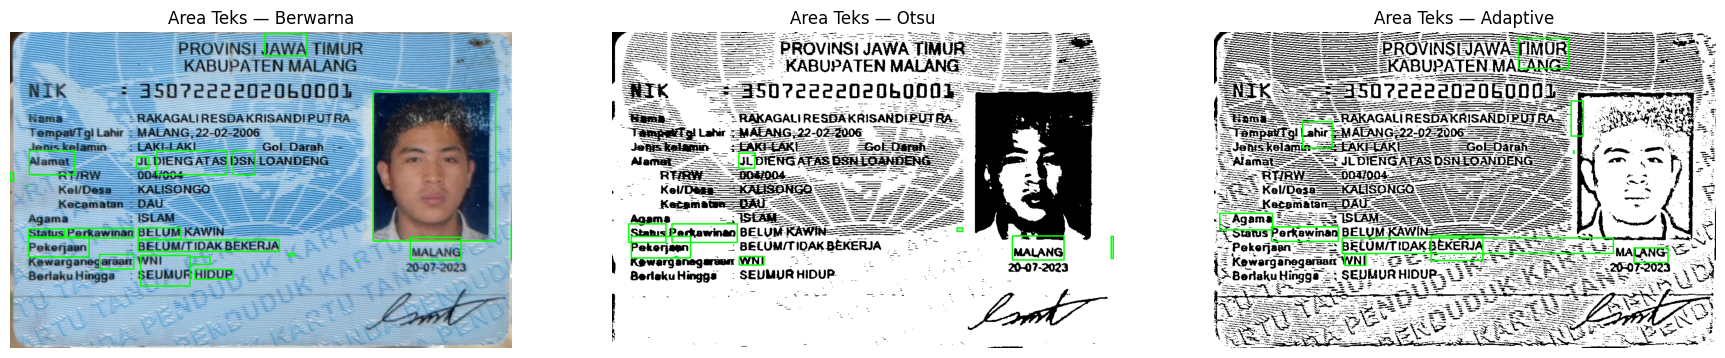

Rata-rata confidence: {'Berwarna': 37.41, 'Otsu': 32.32, 'Adaptive': 24.83}


In [19]:
data_ocr = {}
conf_rata = {}
plt.figure(figsize=(22, 6))
for i, (nama, im) in enumerate(citra_ocr.items()):
    rgb = ke_rgb(im)
    d = pytesseract.image_to_data(rgb, lang=LANG, config=CONFIG, output_type=Output.DICT)
    data_ocr[nama] = d

    kotak = rgb.copy()
    daftar_conf = []
    for j in range(len(d['text'])):
        teks = d['text'][j].strip()
        conf = float(d['conf'][j])
        if teks != '' and conf >= 0:
            daftar_conf.append(conf)
        if teks != '' and conf > BATAS_CONF:               # batas confidence sama untuk ketiganya
            x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
            cv.rectangle(kotak, (x, y), (x + w, y + h), (0, 255, 0), 2)
    conf_rata[nama] = float(np.mean(daftar_conf)) if daftar_conf else 0.0

    plt.subplot(1, 3, i + 1)
    plt.imshow(kotak)
    plt.title(f'Area Teks — {nama}')
    plt.axis('off')
plt.show()
print('Rata-rata confidence:', {k: round(v, 2) for k, v in conf_rata.items()})

### Langkah 4 – Tabel perbandingan 10 kata/angka acuan
Ganti `ACUAN` dengan **10 kata atau angka yang terlihat jelas pada KTP Anda** (isi default hanya contoh untuk KTP Fulan). Penilaian dilakukan pada **seluruh teks hasil OCR**, bukan hanya kata yang diberi kotak.

In [20]:
# >>> EDIT: tulis 10 kata/angka sebenarnya dari KTP Anda <<<
ACUAN = ['PROVINSI', 'JAKARTA', 'SURABAYA', 'LAKI-LAKI', 'ISLAM',
         'KAWIN', 'KARYAWAN', 'SWASTA', 'SEUMUR', 'HIDUP']
assert len(ACUAN) == 10, 'Harus tepat 10 item'

def norm(s):
    # abaikan huruf besar/kecil, spasi, dan tanda baca di awal/akhir
    return re.sub(r'\s+', '', s).lower().strip(' :;,.|_')

def kandidat(teks):
    token = teks.split()
    gabung2 = [token[i] + token[i + 1] for i in range(len(token) - 1)]   # untuk item dua kata
    return token + gabung2

hasil_cek = {}      # nama metode -> list (terbaca_tepat, token_terdekat)
for nama, teks in teks_ocr.items():
    kand = kandidat(teks)
    kand_norm = [norm(k) for k in kand]
    baris = []
    for item in ACUAN:
        n_item = norm(item)
        if n_item in kand_norm:
            baris.append((True, kand[kand_norm.index(n_item)]))
        else:
            dekat = difflib.get_close_matches(n_item, kand_norm, n=1, cutoff=0.5)
            baris.append((False, kand[kand_norm.index(dekat[0])] if dekat else '(tidak terbaca)'))
    hasil_cek[nama] = baris

def sel(nama, i):
    tepat, token = hasil_cek[nama][i]
    return token + (' ✔' if tepat else ' ✘')

tabel = pd.DataFrame({
    'No': range(1, 11),
    'Teks sebenarnya': ACUAN,
    'OCR citra berwarna': [sel('Berwarna', i) for i in range(10)],
    'OCR Otsu': [sel('Otsu', i) for i in range(10)],
    'OCR Adaptive': [sel('Adaptive', i) for i in range(10)],
})
tabel

,No,Teks sebenarnya,OCR citra berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,BROVINSI ✘,PROVINSIJAWA ✘,PROVINSIYAWA ✘
1,2,JAKARTA,JAWA ✘,AATA ✘,SaAA ✘
2,3,SURABAYA,(tidak terbaca) ✘,rama ✘,SaAA ✘
3,4,LAKI-LAKI,(tidak terbaca) ✘,(tidak terbaca) ✘,(tidak terbaca) ✘
4,5,ISLAM,(tidak terbaca) ✘,ama ✘,ISTAM ✘
5,6,KAWIN,KAWIN ✔,KAWIN. ✔,Perkawinan ✘
6,7,KARYAWAN,araan ✘,KAWIN. ✘,Pekerjaan ✘
7,8,SWASTA,—W—Status ✘,AATA ✘,Sasa ✘
8,9,SEUMUR,SEUMUR ✔,SEUMURHIDUP ✘,TIMUR ✘
9,10,HIDUP,HIDUP ✔,SEUMURHIDUP ✘,hi ✘


### Langkah 5 – Persentase kecocokan
`Kecocokan = (jumlah item terbaca tepat / 10) × 100%`. Item yang tidak terbaca dihitung tidak cocok.

In [21]:
nama_tampil = {'Berwarna': 'Berwarna asli', 'Otsu': 'Segmentasi Otsu', 'Adaptive': 'Segmentasi Adaptive'}
ringkasan = pd.DataFrame({
    'Citra masukan OCR': [nama_tampil[n] for n in citra_ocr],
    'Item terbaca tepat': [sum(t for t, _ in hasil_cek[n]) for n in citra_ocr],
    'Kecocokan (%)': [sum(t for t, _ in hasil_cek[n]) / 10 * 100 for n in citra_ocr],
    'Rata-rata confidence': [round(conf_rata[n], 2) for n in citra_ocr],
})
ringkasan

,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,3,30.0,37.41
1,Segmentasi Otsu,1,10.0,32.32
2,Segmentasi Adaptive,0,0.0,24.83


### Pertanyaan analisis
Kode di bawah mencetak **bukti dari data** untuk pertanyaan 1, 2, dan 5. Jawaban tertulis tetap ditulis sendiri berdasarkan hasil percobaan Anda.

In [22]:
# Bukti untuk pertanyaan 1
terbaik = ringkasan.sort_values(['Kecocokan (%)', 'Rata-rata confidence'], ascending=False).iloc[0]
print('1) Citra masukan dengan pembacaan paling tepat:', terbaik['Citra masukan OCR'],
      f"({terbaik['Item terbaca tepat']}/10 = {terbaik['Kecocokan (%)']:.0f}%)")

# Bukti untuk pertanyaan 2: contoh kesalahan pembacaan
print('\n2) Contoh kesalahan pembacaan (acuan -> hasil OCR terdekat):')
for n in citra_ocr:
    salah = [(ACUAN[i], hasil_cek[n][i][1]) for i in range(10) if not hasil_cek[n][i][0]]
    print(f'   {nama_tampil[n]:20s}:', salah if salah else 'tidak ada kesalahan')

# Bukti untuk pertanyaan 3: apakah segmentasi meningkatkan kecocokan dibanding citra berwarna?
dasar = ringkasan.loc[0, 'Kecocokan (%)']
print('\n3) Selisih kecocokan terhadap citra berwarna:')
for _, r in ringkasan.iloc[1:].iterrows():
    print(f"   {r['Citra masukan OCR']:20s}: {r['Kecocokan (%)'] - dasar:+.0f} poin")

# Bukti untuk pertanyaan 5
conf_tertinggi = ringkasan.loc[ringkasan['Rata-rata confidence'].idxmax(), 'Citra masukan OCR']
cocok_tertinggi = ringkasan.loc[ringkasan['Kecocokan (%)'].idxmax(), 'Citra masukan OCR']
print('\n5) Confidence tertinggi :', conf_tertinggi)
print('   Kecocokan tertinggi  :', cocok_tertinggi)
print('   Sama?', conf_tertinggi == cocok_tertinggi)

1) Citra masukan dengan pembacaan paling tepat: Berwarna asli (3/10 = 30%)

2) Contoh kesalahan pembacaan (acuan -> hasil OCR terdekat):
   Berwarna asli       : [('PROVINSI', 'BROVINSI'), ('JAKARTA', 'JAWA'), ('SURABAYA', '(tidak terbaca)'), ('LAKI-LAKI', '(tidak terbaca)'), ('ISLAM', '(tidak terbaca)'), ('KARYAWAN', 'araan'), ('SWASTA', '—W—Status')]
   Segmentasi Otsu     : [('PROVINSI', 'PROVINSIJAWA'), ('JAKARTA', 'AATA'), ('SURABAYA', 'rama'), ('LAKI-LAKI', '(tidak terbaca)'), ('ISLAM', 'ama'), ('KARYAWAN', 'KAWIN.'), ('SWASTA', 'AATA'), ('SEUMUR', 'SEUMURHIDUP'), ('HIDUP', 'SEUMURHIDUP')]
   Segmentasi Adaptive : [('PROVINSI', 'PROVINSIYAWA'), ('JAKARTA', 'SaAA'), ('SURABAYA', 'SaAA'), ('LAKI-LAKI', '(tidak terbaca)'), ('ISLAM', 'ISTAM'), ('KAWIN', 'Perkawinan'), ('KARYAWAN', 'Pekerjaan'), ('SWASTA', 'Sasa'), ('SEUMUR', 'TIMUR'), ('HIDUP', 'hi')]

3) Selisih kecocokan terhadap citra berwarna:
   Segmentasi Otsu     : -20 poin
   Segmentasi Adaptive : -30 poin

5) Confidence tert

```markdown
**Jawaban analisis (isi sendiri setelah menjalankan percobaan):**

1. **Citra masukan yang paling tepat:** Citra Berwarna asli.
   - **Bukti dari tabel:** Item terbaca tepat adalah 3/10 (Kecocokan 30%) dengan rata-rata confidence tertinggi (37.41), sedangkan Otsu hanya 1/10 (10%) dan Adaptive 0/10 (0%).

2. **Dua kesalahan pembacaan (contoh: huruf tertukar, angka salah, teks tidak terbaca):**
   - **(a)** Pada metode *Berwarna*, kata `PROVINSI` terbaca salah menjadi `BROVINSI` (huruf 'P' tertukar dengan 'B').
   - **(b)** Pada metode *Otsu*, kata `ISLAM` terbaca salah menjadi hanya `ama` (sebagian huruf hilang/tidak terbaca penuh).

3. **Apakah segmentasi selalu meningkatkan ketepatan OCR?** Tidak selalu.
   - **Penjelasan:** Berdasarkan hasil percobaan ini, proses segmentasi thresholding justru menurunkan akurasi OCR (Otsu turun -20 poin, Adaptive turun -30 poin dibandingkan citra berwarna asli). Hal ini terjadi karena thresholding yang kurang sempurna dapat memutus piksel karakter huruf atau memunculkan banyak noise di latar belakang.

4. **Pengaruh warna atau pola latar belakang pada pembacaan teks:**
   - **Penjelasan:** Pola latar belakang (seperti peta/watermark pada KTP) memiliki intensitas warna yang dekat dengan teks. Ketika dilakukan thresholding (terutama Adaptive), pola latar belakang ini ikut tersegmentasi dan memunculkan noise bintik-bintik hitam yang mengelilingi teks. Akibatnya, mesin OCR kesulitan membedakan batas karakter huruf asli dari noise latar belakang tersebut, sehingga teks menjadi rusak atau tidak terbaca.

5. **Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?** Ya.
   - **Penjelasan:** Pada uji coba ini, metode *Berwarna asli* memiliki rata-rata confidence tertinggi (37.41) sekaligus kecocokan item riil tertinggi (30%). Meskipun demikian, nilai confidence hanyalah indikator keyakinan mesin OCR dan bukan jaminan mutlak kebenaran pembacaan teks asli.
```